# Clasificación de Animales Salvajes y No Salvajes mediante CNN
**Alumna:** Camila Maldonado

El dataset debe estar en Google Drive dentro de `Mi unidad/animales/` con las carpetas `train/`, `val/` e `inf/`.

In [ ]:
# Celda 1: Librerías, montaje de Drive y semilla (para que los resultados sean reproducibles)
import os
import random
import shutil
import hashlib
import unicodedata

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from PIL import Image
from sklearn.metrics import (
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    precision_score, recall_score, f1_score
)

# Montar Google Drive (solo en Colab; te pedirá permiso la primera vez)
try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    pass  # fuera de Colab no hace falta montar Drive

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# Celda 2: Configuración general (es la única celda que hay que tocar)
# RUTA_ORIGEN: carpeta 'animales' en Drive, con train/, val/ e inf/ dentro
RUTA_ORIGEN = '/content/drive/MyDrive/animales'
# RUTA_INF: fotos nuevas para la visualización (no se usan para entrenar ni evaluar)
RUTA_INF = os.path.join(RUTA_ORIGEN, 'inf')
# Carpeta de trabajo con la copia estandarizada (se crea en /content/, no toca el original)
RUTA_TRABAJO = 'dataset_estandar'

IMG_SIZE = (128, 128)       #IMG_SIZE = (128, 128)   # tamaño fijo de entrada de la red
BATCH_SIZE = 32
EPOCHS = 15     #EPOCHS = 30
MAX_TRAIN_POR_CLASE = 500 #MAX_TRAIN_POR_CLASE = 1000 # balanceo del train
MAX_VAL_POR_CLASE = 100     # balanceo de la validación

EXTENSIONES = {'.jpg', '.jpeg', '.png'}

# Diccionario de traducción: nombre original (inglés o italiano) -> español
# Se usa para estandarizar las carpetas y para mostrar los nombres en los gráficos
ETIQUETAS_ES = {
    'lion': 'León', 'lions': 'León', 'leon': 'León', 'león': 'León',
    'horse': 'Caballo', 'horses': 'Caballo', 'cavallo': 'Caballo', 'caballo': 'Caballo',
    'elephant': 'Elefante', 'elephants': 'Elefante', 'elefante': 'Elefante',
    'dog': 'Perro', 'dogs': 'Perro', 'cane': 'Perro', 'perro': 'Perro',
    'cat': 'Gato', 'cats': 'Gato', 'gatto': 'Gato', 'gato': 'Gato',
    'chicken': 'Gallina', 'gallina': 'Gallina',
    'butterfly': 'Mariposa', 'farfalla': 'Mariposa', 'mariposa': 'Mariposa',
    'cow': 'Vaca', 'mucca': 'Vaca', 'vaca': 'Vaca',
    'sheep': 'Oveja', 'pecora': 'Oveja', 'oveja': 'Oveja',
    'squirrel': 'Ardilla', 'scoiattolo': 'Ardilla', 'ardilla': 'Ardilla',
    'spider': 'Araña', 'ragno': 'Araña', 'arana': 'Araña', 'araña': 'Araña',
}

# Quita tildes y pasa a minúsculas (para usar como nombre de carpeta y en conjuntos)
def carpeta_de(nombre):
    s = unicodedata.normalize('NFKD', nombre).encode('ascii', 'ignore').decode()
    return s.lower()

# Nombre de carpeta -> nombre visible con tildes (para gráficos)
VISIBLE = {carpeta_de(v): v for v in ETIQUETAS_ES.values()}

def nombre_visible(carpeta):
    return VISIBLE.get(carpeta, carpeta)

# Criterio de clasificación (nombres de carpeta sin tildes)
SALVAJES = {'leon', 'elefante', 'mariposa', 'ardilla', 'arana'}
# El caballo se considera doméstico (ver README, sección 'Criterio de clasificación')
NO_SALVAJES = {'caballo', 'perro', 'gato', 'gallina', 'vaca', 'oveja'}

In [ ]:
# Celda 3: Estandarización de archivos y balanceo
# Copia train y val a dataset_estandar con nombres uniformes (leon_0001.jpg, perro_0001.jpg...).
# Convierte cada imagen a RGB y la guarda como .jpg: unifica .jpg/.jpeg/.png y descarta corruptas.
def estandarizar_dataset(origen, destino):
    if os.path.exists(destino):
        shutil.rmtree(destino)  # empezar de cero en cada ejecución

    contador = {}  # numera las imágenes por (split, clase)
    descartadas = 0

    for split in ['train', 'val']:
        ruta_split = os.path.join(origen, split)
        for carpeta in sorted(os.listdir(ruta_split)):
            ruta_clase = os.path.join(ruta_split, carpeta)
            clase = ETIQUETAS_ES.get(carpeta.lower())
            if not os.path.isdir(ruta_clase) or clase is None:
                print('Carpeta omitida:', carpeta)
                continue

            nombre_clase = carpeta_de(clase)
            dir_destino = os.path.join(destino, split, nombre_clase)
            os.makedirs(dir_destino, exist_ok=True)

            for f in sorted(os.listdir(ruta_clase)):
                if os.path.splitext(f)[1].lower() not in EXTENSIONES:
                    continue
                try:
                    with Image.open(os.path.join(ruta_clase, f)) as im:
                        rgb = im.convert('RGB')
                except Exception:
                    descartadas += 1
                    continue

                clave = (split, nombre_clase)
                contador[clave] = contador.get(clave, 0) + 1
                nuevo = f'{nombre_clase}_{contador[clave]:04d}.jpg'
                rgb.save(os.path.join(dir_destino, nuevo), 'JPEG', quality=95)

    print('Estandarización lista. Imágenes corruptas descartadas:', descartadas)
    return destino

# Calcula el hash MD5 de un archivo (sirve para detectar fotos idénticas)
def md5(ruta):
    with open(ruta, 'rb') as fh:
        return hashlib.md5(fh.read()).hexdigest()

# Elimina del train las imágenes idénticas a alguna de val (evita inflar las métricas)
def quitar_duplicados_train_val(ruta):
    hashes_val = set()
    for clase in os.listdir(os.path.join(ruta, 'val')):
        for f in os.listdir(os.path.join(ruta, 'val', clase)):
            hashes_val.add(md5(os.path.join(ruta, 'val', clase, f)))

    eliminadas = 0
    for clase in os.listdir(os.path.join(ruta, 'train')):
        for f in os.listdir(os.path.join(ruta, 'train', clase)):
            p = os.path.join(ruta, 'train', clase, f)
            if md5(p) in hashes_val:
                os.remove(p)
                eliminadas += 1
    print('Duplicados exactos train/val eliminados:', eliminadas)

# Deja como máximo 'maximo' imágenes por clase en el split indicado (selección aleatoria con semilla)
def balancear(ruta, split, maximo):
    ruta_split = os.path.join(ruta, split)
    for clase in os.listdir(ruta_split):
        d = os.path.join(ruta_split, clase)
        archivos = sorted(os.listdir(d))
        if len(archivos) > maximo:
            random.Random(SEED).shuffle(archivos)
            for f in archivos[maximo:]:
                os.remove(os.path.join(d, f))

ruta_estandar = estandarizar_dataset(RUTA_ORIGEN, RUTA_TRABAJO)
quitar_duplicados_train_val(ruta_estandar)
balancear(ruta_estandar, 'train', MAX_TRAIN_POR_CLASE)
balancear(ruta_estandar, 'val', MAX_VAL_POR_CLASE)

Estandarización lista. Imágenes corruptas descartadas: 0
Duplicados exactos train/val eliminados: 0


In [ ]:
# Celda 4: Conteo por clase (verificación del balanceo)
for split in ['train', 'val']:
    print(split.upper())
    for clase in sorted(os.listdir(os.path.join(ruta_estandar, split))):
        n = len(os.listdir(os.path.join(ruta_estandar, split, clase)))
        tipo = 'salvaje' if clase in SALVAJES else 'no salvaje'
        print(f'  {nombre_visible(clase):<12} {n:>5}  ({tipo})')
    print()

TRAIN
  Araña          500  (salvaje)
  Ardilla        500  (salvaje)
  Caballo        500  (no salvaje)
  Elefante       500  (salvaje)
  Gallina        500  (no salvaje)
  Gato           500  (no salvaje)
  León           500  (salvaje)
  Mariposa       500  (salvaje)
  Oveja          500  (no salvaje)
  Perro          500  (no salvaje)
  Vaca           500  (no salvaje)

VAL
  Araña          100  (salvaje)
  Ardilla        100  (salvaje)
  Caballo        100  (no salvaje)
  Elefante       100  (salvaje)
  Gallina        100  (no salvaje)
  Gato           100  (no salvaje)
  León           100  (salvaje)
  Mariposa       100  (salvaje)
  Oveja          100  (no salvaje)
  Perro          100  (no salvaje)
  Vaca           100  (no salvaje)



In [ ]:
# Celda 5: Carga de datos con Keras (redimensionado a IMG_SIZE)
# Las etiquetas por especie se cargan y luego se convierten a binario (salvaje = 1).
ds_train = keras.utils.image_dataset_from_directory(
    os.path.join(ruta_estandar, 'train'),
    labels='inferred', label_mode='int',
    image_size=IMG_SIZE, batch_size=BATCH_SIZE,
    shuffle=True, seed=SEED,
)
ds_val = keras.utils.image_dataset_from_directory(
    os.path.join(ruta_estandar, 'val'),
    labels='inferred', label_mode='int',
    image_size=IMG_SIZE, batch_size=BATCH_SIZE,
    shuffle=False,  # validación sin mezclar, para evaluar siempre en el mismo orden
)
class_names = ds_train.class_names
print('Clases (orden de la red):', [nombre_visible(c) for c in class_names])

# Vector: 1 si la especie es salvaje, 0 si no
es_salvaje_np = np.array([1 if c in SALVAJES else 0 for c in class_names], dtype=np.float32)
es_salvaje = tf.constant(es_salvaje_np)

# Convierte la etiqueta de especie en etiqueta binaria (salvaje = 1 / no salvaje = 0)
def a_binario(x, y_especie):
    return x, tf.gather(es_salvaje, y_especie)

ds_train_bin = ds_train.map(a_binario, num_parallel_calls=tf.data.AUTOTUNE).prefetch(tf.data.AUTOTUNE)
ds_val_bin = ds_val.map(a_binario, num_parallel_calls=tf.data.AUTOTUNE).prefetch(tf.data.AUTOTUNE)

Found 5500 files belonging to 11 classes.
Found 1100 files belonging to 11 classes.
Clases (orden de la red): ['Araña', 'Ardilla', 'Caballo', 'Elefante', 'Gallina', 'Gato', 'León', 'Mariposa', 'Oveja', 'Perro', 'Vaca']


Verificando imágenes en: /content/drive/MyDrive/animales/inf
Se encontraron 11 imágenes para inferencia.


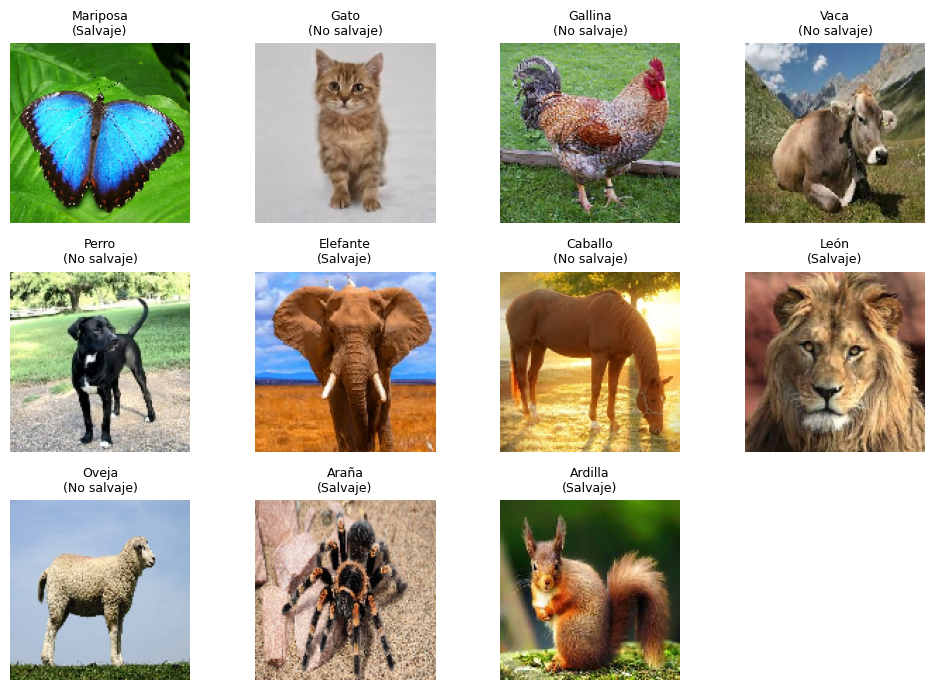

In [ ]:
# Celda 6: Visualización de fotos de la carpeta inf (no usadas en entrenamiento)
# Se asume que las fotos están sueltas en 'inf' y contienen el nombre del animal en inglés en su nombre de archivo.
import os
import matplotlib.pyplot as plt
from tensorflow.keras.utils import load_img, img_to_array

print(f"Verificando imágenes en: {RUTA_INF}")

if not os.path.exists(RUTA_INF):
    print("❌ La ruta de inferencia no existe en tu Google Drive.")
else:
    archivos = sorted(os.listdir(RUTA_INF))
    # Filtrar solo archivos de imagen permitidos
    imagenes = [f for f in archivos if os.path.splitext(f)[1].lower() in EXTENSIONES]

    if len(imagenes) == 0:
        print("⚠ No se encontraron imágenes válidas (.jpg, .jpeg, .png) sueltas en la carpeta 'inf'.")
    else:
        print(f"Se encontraron {len(imagenes)} imágenes para inferencia.")

        # Intentar determinar la clase (especie) desde el nombre del archivo en inglés
        def obtener_especie_de_nombre(nombre_archivo):
            nombre_min = nombre_archivo.lower()
            for ingles, espanol in ETIQUETAS_ES.items():
                if ingles in nombre_min:
                    return carpeta_de(espanol)
            return "desconocido"

        plt.figure(figsize=(10, 7))
        mostradas = 0

        for f in imagenes:
            if mostradas >= 12:
                break

            ruta_completa = os.path.join(RUTA_INF, f)
            try:
                # Cargar y redimensionar la imagen para que coincida con el tamaño del modelo
                img = load_img(ruta_completa, target_size=IMG_SIZE)

                # Identificar la especie basándose en el nombre del archivo
                especie = obtener_especie_de_nombre(f)
                if especie != "desconocido":
                    categoria = 'Salvaje' if especie in SALVAJES else 'No salvaje'
                    titulo = f"{nombre_visible(especie)}\n({categoria})"
                else:
                    titulo = f"{f}\n(Desconocido)"

                plt.subplot(3, 4, mostradas + 1)
                plt.imshow(img)
                plt.title(titulo, fontsize=9)
                plt.axis('off')
                mostradas += 1
            except Exception as e:
                print(f"No se pudo cargar la imagen {f}: {e}")

        plt.tight_layout()
        plt.show()

>## Arquitectura de la red neuronal convolucional (CNN)
>
>La entrada del modelo está configurada para recibir imágenes RGB de 96x96 píxeles. Primero se realiza una normalización de los valores de los píxeles, llevándolos de un rango de 0 a 255 a uno de 0 a 1.
>
>Después se aplican cuatro capas convolucionales (`Conv2D`), con 32, 64, 128 y 256 filtros de 3x3. Elegí utilizar diferentes cantidades de filtros para que la red pueda ir aprendiendo características cada vez más complejas de las imágenes.
>
>También utilizo `padding='same'` para conservar las dimensiones de los mapas de características y la función ReLU para introducir no linealidad. Como las imágenes tienen tres canales de color (RGB), la red procesa los tres canales de entrada.
>
>Entre las capas convolucionales incorporé `BatchNormalization` y `MaxPooling2D`. La primera ayuda a estabilizar el entrenamiento, mientras que la segunda reduce el tamaño de los mapas de características, conservando la información más importante.
>
>Para finalizar la extracción de características utilizo `GlobalAveragePooling2D` en lugar de Flatten. Esta capa calcula el promedio de cada mapa de características y genera un vector más reducido para alimentar las capas densas.

In [ ]:
# Celda 7: Arquitectura de la CNN
# Preprocesamiento dentro del modelo: aumentación (solo en entrenamiento) y normalización 0-1.
def construir_modelo():
    modelo = keras.Sequential([
        layers.Input(shape=IMG_SIZE + (3,)),

        # Aumentación de datos (solo activa durante el entrenamiento)
        layers.RandomFlip('horizontal'),
        layers.RandomRotation(0.1),
        layers.RandomZoom(0.1),

        # Normalización: píxeles de 0-255 a 0-1
        layers.Rescaling(1.0 / 255),

        # Bloques convolucionales: extraen bordes, texturas y formas
        layers.Conv2D(32, 3, padding='same', activation='relu'),
        layers.BatchNormalization(),
        layers.MaxPooling2D(),
        layers.Conv2D(64, 3, padding='same', activation='relu'),
        layers.BatchNormalization(),
        layers.MaxPooling2D(),
        layers.Conv2D(128, 3, padding='same', activation='relu'),
        layers.BatchNormalization(),
        layers.MaxPooling2D(),
        layers.Conv2D(256, 3, padding='same', activation='relu'),
        layers.BatchNormalization(),
        layers.MaxPooling2D(),

        # Clasificador denso
        layers.GlobalAveragePooling2D(),
        layers.Dense(128, activation='relu'),
        layers.Dropout(0.5),  # reduce el sobreajuste
        layers.Dense(1, activation='sigmoid'),  # probabilidad de ser salvaje
    ])
    modelo.compile(
        optimizer=keras.optimizers.Adam(learning_rate=1e-3),
        loss='binary_crossentropy',
        metrics=['accuracy', keras.metrics.AUC(name='auc')],
    )
    return modelo

model = construir_modelo()
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_flip (RandomFlip)        │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ (None, 128, 128, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom (RandomZoom)        │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128, 128, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 16, 16, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 8, 8, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 423,361 (1.61 MB)

 Trainable params: 422,401 (1.61 MB)

 Non-trainable params: 960 (3.75 KB)

>## Clasificación y entrenamiento del modelo
>
>Una vez extraídas las características de las imágenes, estas pasan a una capa densa de 128 neuronas con activación ReLU, que se encarga de combinar la información aprendida.
>
>También incorporé `Dropout` con un valor de 0.5 para reducir el sobreajuste, evitando que la red dependa demasiado de determinadas neuronas.
>
>La última capa tiene una sola neurona con activación Sigmoid, ya que el objetivo es realizar una clasificación binaria: animal salvaje o no salvaje. El resultado es un valor entre 0 y 1 que representa la probabilidad de pertenecer a la categoría de animal salvaje.
>
>Para entrenar el modelo utilizo el optimizador Adam y la función de pérdida Binary Crossentropy. Durante el entrenamiento se calcula el error de las predicciones y, mediante backpropagation, se ajustan los pesos de la red para intentar mejorar los resultados.
>
>El entrenamiento se realiza durante varias épocas y se utilizan mecanismos como EarlyStopping y ReduceLROnPlateau para controlar el proceso y evitar entrenamientos innecesarios.

In [ ]:
# Celda 8: Entrenamiento
callbacks = [
    # Corta el entrenamiento si val_loss no mejora y restaura los mejores pesos
    keras.callbacks.EarlyStopping(monitor='val_loss', patience=6, restore_best_weights=True),
    # Reduce la tasa de aprendizaje cuando se estanca
    keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, verbose=1),
]

history = model.fit(
    ds_train_bin,
    validation_data=ds_val_bin,
    epochs=EPOCHS,
    callbacks=callbacks,
)

Epoch 1/15
172/172 ━━━━━━━━━━━━━━━━━━━━ 246s 1s/step - accuracy: 0.6780 - auc: 0.7196 - loss: 0.6391 - val_accuracy: 0.4527 - val_auc: 0.6090 - val_loss: 0.9830 - learning_rate: 0.0010
Epoch 2/15
172/172 ━━━━━━━━━━━━━━━━━━━━ 253s 1s/step - accuracy: 0.7355 - auc: 0.8013 - loss: 0.5397 - val_accuracy: 0.5700 - val_auc: 0.7574 - val_loss: 0.7866 - learning_rate: 0.0010
Epoch 3/15
172/172 ━━━━━━━━━━━━━━━━━━━━ 278s 2s/step - accuracy: 0.7709 - auc: 0.8397 - loss: 0.4952 - val_accuracy: 0.7891 - val_auc: 0.8858 - val_loss: 0.4456 - learning_rate: 0.0010
Epoch 4/15
172/172 ━━━━━━━━━━━━━━━━━━━━ 254s 1s/step - accuracy: 0.7845 - auc: 0.8595 - loss: 0.4681 - val_accuracy: 0.7200 - val_auc: 0.7931 - val_loss: 0.6054 - learning_rate: 0.0010
Epoch 5/15
172/172 ━━━━━━━━━━━━━━━━━━━━ 249s 1s/step - accuracy: 0.8004 - auc: 0.8786 - loss: 0.4358 - val_accuracy: 0.7455 - val_auc: 0.8372 - val_loss: 0.5226 - learning_rate: 0.0010
Epoch 6/15
172/172 ━━━━━━━━━━━━━━━━━━━━ 269s 1s/step - accuracy: 0.8144 - a

>## Curvas de aprendizaje
>
>Para observar cómo evoluciona el entrenamiento, se generan dos gráficos que muestran la pérdida y la precisión durante cada época, tanto para los datos de entrenamiento como para los de validación.
>
>Esto permite comparar el comportamiento del modelo y observar si está aprendiendo correctamente o si existe sobreajuste, que ocurre cuando funciona bien con las imágenes de entrenamiento pero tiene dificultades con imágenes que no utilizó para aprender.

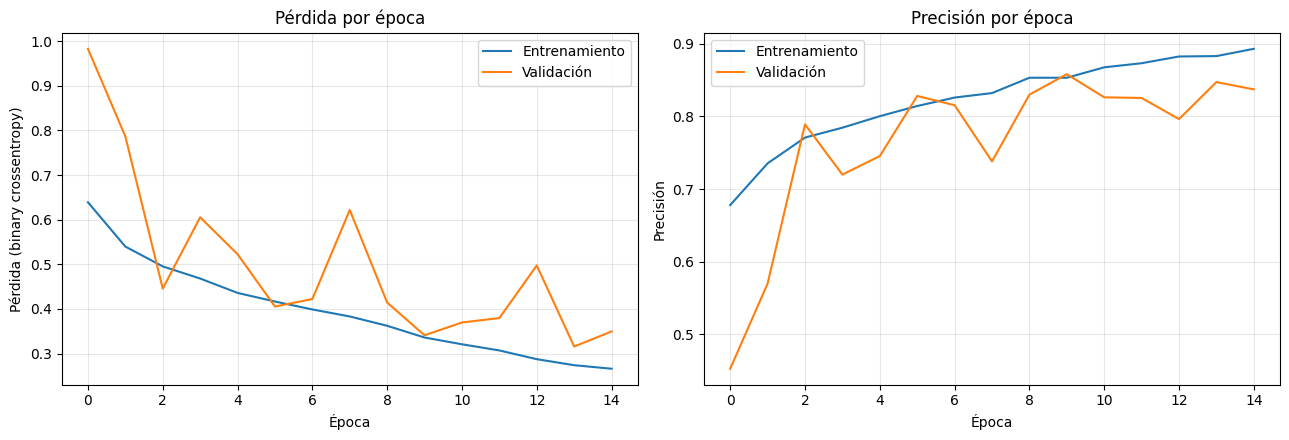

In [ ]:
# Celda 9: Curvas de aprendizaje (pérdida y precisión por época)
def graficar_curvas(hist):
    fig, ejes = plt.subplots(1, 2, figsize=(13, 4.5))

    ejes[0].plot(hist.history['loss'], label='Entrenamiento')
    ejes[0].plot(hist.history['val_loss'], label='Validación')
    ejes[0].set_title('Pérdida por época')
    ejes[0].set_xlabel('Época')
    ejes[0].set_ylabel('Pérdida (binary crossentropy)')
    ejes[0].legend()
    ejes[0].grid(alpha=0.3)

    ejes[1].plot(hist.history['accuracy'], label='Entrenamiento')
    ejes[1].plot(hist.history['val_accuracy'], label='Validación')
    ejes[1].set_title('Precisión por época')
    ejes[1].set_xlabel('Época')
    ejes[1].set_ylabel('Precisión')
    ejes[1].legend()
    ejes[1].grid(alpha=0.3)

    plt.tight_layout()
    plt.show()

graficar_curvas(history)

>## Evaluación del modelo
>
>Una vez finalizado el entrenamiento, se evalúa el modelo utilizando las imágenes del conjunto de validación.
>
>Para analizar su rendimiento se utilizan distintas métricas:
>
>- **Accuracy:** indica el porcentaje total de imágenes clasificadas correctamente.
>- **Matriz de confusión:** permite observar los aciertos y errores de clasificación.
>- **Precision:** indica cuántas de las imágenes clasificadas como salvajes realmente lo eran.
>- **Recall:** muestra cuántos de los animales salvajes reales logró identificar el modelo.
>- **F1-Score:** combina Precision y Recall para evaluar el equilibrio entre ambas métricas.
>- **AUC:** permite medir la capacidad del modelo para diferenciar entre las dos categorías.
>
>Con estas métricas se puede tener una visión más completa del funcionamiento de la red y no depender solamente del porcentaje de aciertos.

Precisión (accuracy) en validación: 84.73%
AUC en validación: 0.957

Accuracy global: 84.73%
Precision (Salvaje): 92.13%
Recall / sensibilidad (Salvaje): 72.60%
F1-score (Salvaje): 81.21%
AUC en validación: 0.957

              precision    recall  f1-score   support

  No salvaje       0.81      0.95      0.87       600
     Salvaje       0.92      0.73      0.81       500

    accuracy                           0.85      1100
   macro avg       0.86      0.84      0.84      1100
weighted avg       0.86      0.85      0.84      1100



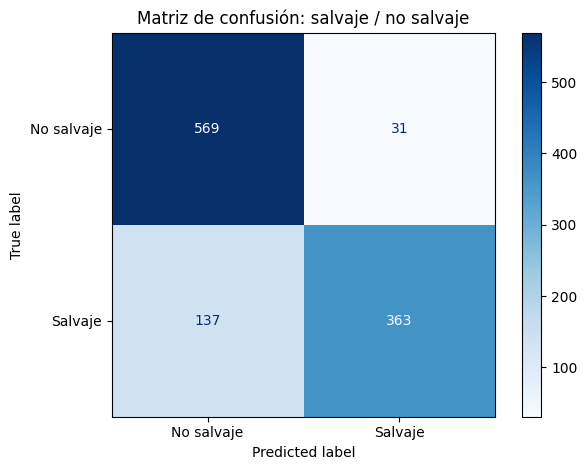

In [ ]:
# Celda 10: Evaluación en validación (métricas binarias)
y_prob, y_esp = [], []
for x, y in ds_val:  # ds_val conserva la etiqueta de especie
    y_prob.append(model.predict(x, verbose=0).ravel())
    y_esp.append(y.numpy())
y_prob = np.concatenate(y_prob)
y_esp = np.concatenate(y_esp)

y_true = es_salvaje_np[y_esp].astype(int)  # 1 = salvaje, según la especie real
y_pred = (y_prob >= 0.5).astype(int)       # umbral 0.5

loss, acc, auc = model.evaluate(ds_val_bin, verbose=0)
print(f'Precisión (accuracy) en validación: {acc:.2%}')
print(f'AUC en validación: {auc:.3f}')
print()

# Métricas globales: accuracy, precision, recall y F1 para la clase positiva (Salvaje=1)
# Accuracy: proporción total de predicciones correctas.
accuracy_global = np.mean(y_true == y_pred)
# Precision: de las imágenes predichas como salvajes, cuántas eran realmente salvajes.
precision_salvaje = precision_score(y_true, y_pred, pos_label=1, zero_division=0)
# Recall/sensibilidad: de las imágenes realmente salvajes, cuántas detectó la red.
recall_salvaje = recall_score(y_true, y_pred, pos_label=1, zero_division=0)
# F1: media armónica entre precision y recall.
f1_salvaje = f1_score(y_true, y_pred, pos_label=1, zero_division=0)
print(f'Accuracy global: {accuracy_global:.2%}')
print(f'Precision (Salvaje): {precision_salvaje:.2%}')
print(f'Recall / sensibilidad (Salvaje): {recall_salvaje:.2%}')
print(f'F1-score (Salvaje): {f1_salvaje:.2%}')
print(f'AUC en validación: {auc:.3f}\n')

# Reporte por categoría: incluye precision, recall, F1-score y cantidad de ejemplos (support).
print(classification_report(y_true, y_pred, labels=[0, 1],
                            target_names=['No salvaje', 'Salvaje'], zero_division=0))

# Matriz de confusión: filas = clase real, columnas = clase predicha.
# La diagonal son aciertos; las celdas fuera de la diagonal son errores.
cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
disp = ConfusionMatrixDisplay(cm, display_labels=['No salvaje', 'Salvaje'])
disp.plot(cmap='Blues', values_format='d')
plt.title('Matriz de confusión: salvaje / no salvaje')
plt.tight_layout()
plt.show()

Aciertos por especie:
  Araña        66.00%
  Ardilla      45.00%
  Caballo      81.00%
  Elefante     76.00%
  Gallina      94.00%
  Gato         99.00%
  León         95.00%
  Mariposa     81.00%
  Oveja        98.00%
  Perro        100.00%
  Vaca         97.00%


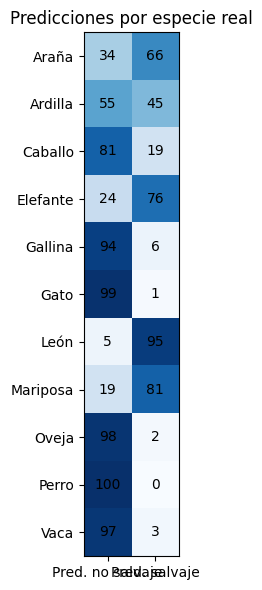

In [ ]:
# Celda 11: Aciertos por especie y confusiones entre especies
print('Aciertos por especie:')
for i, carpeta in enumerate(class_names):
    mascara = y_esp == i
    aciertos = (y_pred[mascara] == int(es_salvaje_np[i])).mean()
    print(f'  {nombre_visible(carpeta):<12} {aciertos:.2%}')

# Matriz de predicciones por especie real (grupo predicho: salvaje / no salvaje)
etiquetas = [nombre_visible(c) for c in class_names]
cm_esp = np.zeros((len(class_names), 2), dtype=int)
for real, pred in zip(y_esp, y_pred):
    cm_esp[real, pred] += 1

fig, ax = plt.subplots(figsize=(7, 6))
ax.imshow(cm_esp, cmap='Blues')
ax.set_xticks([0, 1], ['Pred. no salvaje', 'Pred. salvaje'])
ax.set_yticks(range(len(etiquetas)), etiquetas)
for i in range(cm_esp.shape[0]):
    for j in range(cm_esp.shape[1]):
        ax.text(j, i, cm_esp[i, j], ha='center', va='center')
ax.set_title('Predicciones por especie real')
plt.tight_layout()
plt.show()

Saving 115.jpeg to 115.jpeg


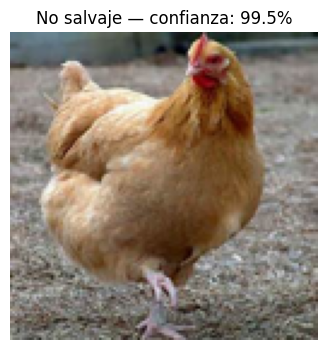

Predicción: No salvaje
Probabilidad de ser salvaje: 0.5%


In [ ]:
# Celda 12: Probar el modelo con una imagen elegida por el usuario
# En Google Colab, permite subir una imagen y predice si el animal es salvaje.

from google.colab import files

archivos_subidos = files.upload()

if archivos_subidos:
    # Toma la primera imagen subida
    nombre_archivo = next(iter(archivos_subidos))

    try:
        # Abre la imagen, la convierte a RGB y la redimensiona al tamaño que espera la CNN
        with Image.open(nombre_archivo) as im:
            imagen = im.convert("RGB").resize((IMG_SIZE[1], IMG_SIZE[0]))

        # Prepara la imagen como un lote de una sola imagen.
        # La normalización de píxeles la aplica el modelo.
        arreglo = np.asarray(imagen, dtype=np.float32)[None, ...]

        # Predice la probabilidad de que sea salvaje
        prob_salvaje = float(model.predict(arreglo, verbose=0)[0, 0])

        # Usa 0.5 como umbral para decidir la categoría
        if prob_salvaje >= 0.5:
            categoria = "Salvaje"
            confianza = prob_salvaje
        else:
            categoria = "No salvaje"
            confianza = 1 - prob_salvaje

        # Muestra la imagen y el resultado
        plt.figure(figsize=(4, 4))
        plt.imshow(imagen)
        plt.axis("off")
        plt.title(f"{categoria} — confianza: {confianza:.1%}")
        plt.show()

        print(f"Predicción: {categoria}")
        print(f"Probabilidad de ser salvaje: {prob_salvaje:.1%}")

    except Exception as error:
        print("No se pudo procesar el archivo. Subí una imagen JPG, JPEG o PNG.")
        print("Detalle:", error)
else:
    print("No se seleccionó ninguna imagen.")


In [ ]:
# Celda 12: Guardar el modelo entrenado
model.save('modelo_salvajes_cnn.keras')
print('Modelo guardado en modelo_salvajes_cnn.keras')

Modelo guardado en modelo_salvajes_cnn.keras
